# Declaring Hyperparametrs

In [11]:
CYCLE_COUNT = 0 # No Of Strain Cycle
HIGH = 0 # High Value in a cycle
LOW = 99999 # Low Value in a Cycle
CAL_MOVEMENT = 0 # Net difference between high and low in calibration
Q = 0.80 # Sensitivity of cycle while growing
Q1 = 0.70 # Sensitivity of cycle while falling
GAIN_CHANGE = Q * CAL_MOVEMENT # change after which cycle will be valid
LOSS_CHANGE = Q1 * CAL_MOVEMENT # change for which a cycle will continue
CALIBRATION_CYCLE_COUNT = 10
def movement():
    return HIGH - LOW

# Defining Imports

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Getting dataset Ready

In [13]:
data_actual = pd.read_csv('dataset/r502010.csv')['Value ']
data_actual.head()
data = data_actual[0:5250]
data.shape

(5250,)

In [14]:
for i in range(0,CALIBRATION_CYCLE_COUNT):
    count = 0
    HIGH = 0 # High Value in a cycle
    LOW = 99999 # Low Value in a Cycle
    print("Give calibration cycle no : ", i+1)
    for val in data[525*i:525*(i+1)]:
        # print(val)
        count+=1
        if val >= HIGH:
            HIGH = val
        elif val <= LOW:
            LOW = val
        if count>=525:
            # print("count break", val)
            count=0
            break
    print(HIGH, LOW)
    CAL_MOVEMENT += movement()
CAL_MOVEMENT /= CALIBRATION_CYCLE_COUNT
GAIN_CHANGE = Q * CAL_MOVEMENT # change after which cycle will be valid
LOSS_CHANGE = Q1 * CAL_MOVEMENT # change for which a cycle will continue
print(" New Calibration Movement is : ", CAL_MOVEMENT)
print(" Gain Change is : ", GAIN_CHANGE)
print(" Loss Change is : ", LOSS_CHANGE)

Give calibration cycle no :  1
5395.3413 4248.4497
Give calibration cycle no :  2
5398.47509 4535.68164
Give calibration cycle no :  3
5456.81982 4495.58398
Give calibration cycle no :  4
5335.51074 4402.39208
Give calibration cycle no :  5
5286.12255 4405.74072
Give calibration cycle no :  6
5458.25976 4364.31054
Give calibration cycle no :  7
5332.0913 4451.53808
Give calibration cycle no :  8
5306.90429 4294.03417
Give calibration cycle no :  9
5361.69824 4265.80566
Give calibration cycle no :  10
5368.26708 4289.65625
 New Calibration Movement is :  994.6297349999999
 Gain Change is :  795.7037879999999
 Loss Change is :  696.2408144999998


5356.09375
5349.74609
5315.0874
5326.53955
5220.99804
5222.41894
5228.00488
5226.32568
5187.32714
5322.88964
5317.3247
5267.97314
5124.80224
5145.09277
5352.53125
5061.87548
5188.54589
5133.26171
5139.2207
5282.93212
4311.86083
NET CYCLES   21


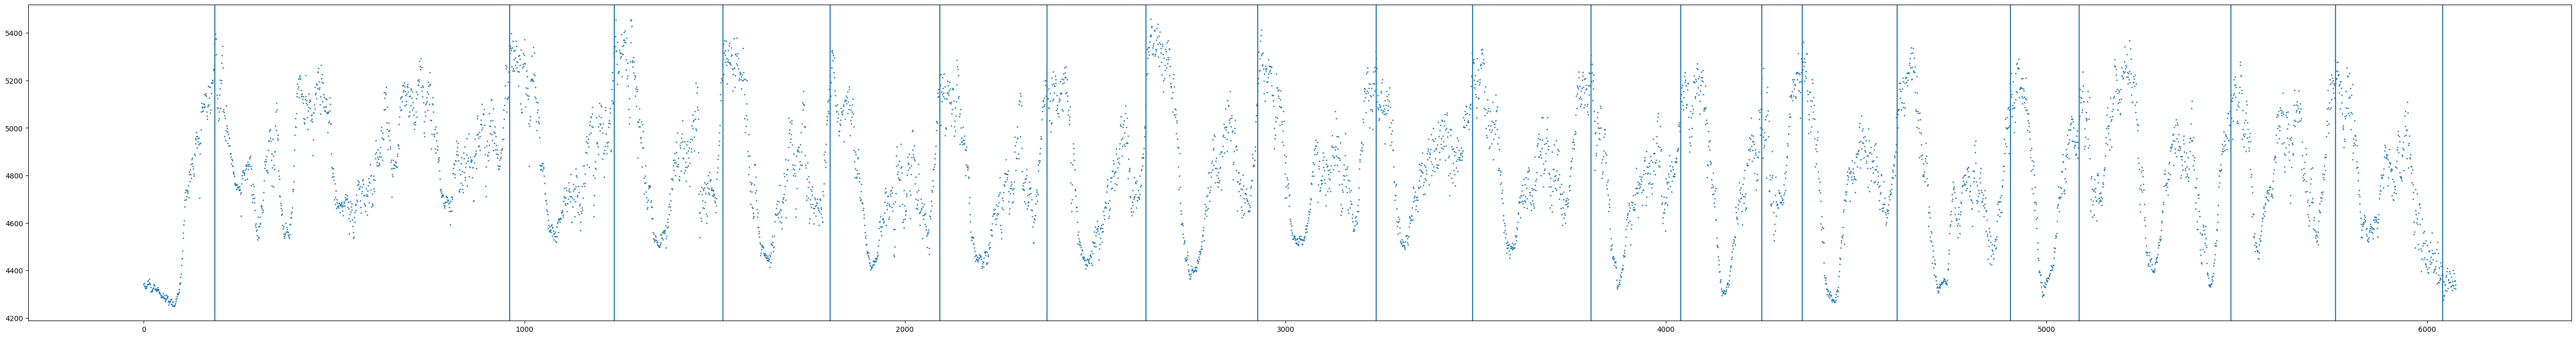

In [15]:
i = 0 # variable to decide which iteration the loop is in
k = 1 # 1 while we apply stain and 0 when we remove strain
count=0
HIGH1 = HIGH
LOW1 = LOW
fig = plt.figure(figsize=(64,8))
plt.scatter(np.arange(0, data_actual.shape[0], 1, dtype=int), data_actual, s=1)
for val in data_actual:
    count+=1
    if i==0 and val< LOW1:
        HIGH1 = val
        LOW1  = val
        HIGH = LOW1
        LOW  = HIGH1
        i+=1
        # print("initial high and low value ", HIGH1, LOW1)
    else:
        if i==0:
            HIGH = LOW1
            LOW  = HIGH1
            i+=1
        if val >= HIGH:
            HIGH = val
            # print("high value changed ", HIGH)
            if k==0:
                LOW = HIGH
                LOW1 = LOW
                HIGH1 = HIGH
        if val <= LOW:
            LOW = val
            # print("low value changed ", LOW)
        MOVEMENT = movement()
        # print("MOVEMENT FOUND : ", MOVEMENT)
        if k==1:
            if MOVEMENT >= GAIN_CHANGE:
                # print(HIGH1, HIGH, LOW1, LOW)
                if HIGH-HIGH1 > LOW-LOW1:
                    CYCLE_COUNT+=1
                    plt.axvline(count, 0, 1, label='pyplot vertical line')
                    print(count)
                    print(val)
                    # print("New Cycle Detected ", CYCLE_COUNT)
                    k=0
                    LOW = HIGH
                    HIGH1 = HIGH
                    LOW1 = LOW
                else:
                    HIGH = LOW
        elif k==0:
            if MOVEMENT >= LOSS_CHANGE:
                # print("MOVEMENT IS MORE THAN LOSS CHANGE")
                # print(HIGH1, HIGH, LOW1, LOW)
                if HIGH-HIGH1 < LOW1-LOW:
                    LOW1 = val
                    HIGH1 = val
                    i = 0
                    k = 1
print("NET CYCLES  ", CYCLE_COUNT)
plt.show()